# Final combined model: trend + inflation + twins in one portfolio

**What it is.** Three forecasts per asset, added together and sized as one book (`src/final_model.py`):

| sleeve | assets | rule |
|---|---|---|
| trend | all 27 | Jaakko's slow pick: EWMAC 32/128 + 64/256 and 12-month momentum, 50/50, capped |
| inflation | 5 bonds, 5 stocks | CPI growth of the asset's moon over k days, minus its trailing 3-year mean, z-scored on a trailing 3-year window. Bonds: −tanh(z), k = 60. Stocks: −tanh(z), k = 120 |
| twins | pairs found by rule | pairs whose 5-day changes correlate > 0.8 on all data up to T. −tanh(z/2) of the log spread vs its 1-year mean |

Each sleeve gets the same risk budget (its forecast is divided by the trailing volatility of its own P&L). The sum goes through Jaakko's sizing: units = forecast / vol, book scaled to constant ex-ante risk, 30% daily glide. Risk caps: twin legs share one budget in trend, the bond block is capped at 2 bets, `ultrapure_silicon` gets half weight.

**Rules followed.** Positions at T use data up to T only. Every normalisation is trailing. All parameters were fixed before scoring; the single choice made on data (twins in or out) used 1997–2009 only. 2009–2016 is a check.

This notebook only displays what `final_validation.py` computes, so the numbers here and in `FINAL_RESULTS.md` are the same. It runs in about 15 seconds.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl
import matplotlib.pyplot as plt
from IPython.display import display
import final_validation as fv          # runs the whole validation (about 10 s)
ev, fm, va = fv.ev, fv.fm, fv.va
%matplotlib inline

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COL = {"trend only": "#2a78d6", "inflation only": "#eb6834", "twins only": "#1baf7a", "final": INK}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "font.size": 9, "legend.frameon": False, "figure.dpi": 110,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})
ERA_COLS = list(fv.ERAS)
def show(df, grad=None):
    s = df.style.format(precision=2).hide(axis="index")
    if grad: s = s.background_gradient(cmap="RdYlGn", vmin=-0.5, vmax=1.5, subset=grad)
    display(s)
print(f"final model = {fv.FINAL}")
print(f"scored from {fv.START} (first day every sleeve holds a position) to {fv.d[-1]}")
print("eras:", {k: (str(a), str(b)) for k, (a, b) in fv.ERAS.items()})

final model = trend + inflation + twins
scored from 1997-05-22 (first day every sleeve holds a position) to 2016-12-30
eras: {'1997-2002': ('1997-05-22', '2002-05-01'), '2002-2009': ('2002-05-01', '2009-08-28'), '2009-2016': ('2009-08-28', '2016-12-30')}


## 1. Performance table

Adjusted Sharpe for the full period and the three eras, then the Lynx key figures. The rows above "twins only" are the build-up of the model; the last three rows are references. `bias` is the position bias (0 = no long or short tilt).

In [2]:
show(fv.main, grad=["full"] + ERA_COLS)

model,full,1997-2002,2002-2009,2009-2016,sharpe,sharpe 1d lag,2x costs,skew,kurt,holding d,bias
Lynx 50d baseline,0.32,-0.07,0.55,0.28,0.32,0.20,0.19,0.14,6.28,15.85,0.02
trend only,0.78,1.44,0.75,0.30,0.85,0.85,0.76,-0.22,4.72,64.66,0.05
inflation only,0.61,0.47,0.88,0.26,0.64,0.66,0.58,-0.06,5.30,50.99,0.02
trend + inflation,0.87,1.00,1.09,0.26,0.94,0.95,0.84,-0.14,4.44,57.15,-0.01
trend + inflation + twins (FINAL),1.06,1.43,1.20,0.53,1.13,1.12,0.98,-0.07,3.90,38.55,0.01
final + Kristofer stop overlay,1.10,1.74,1.22,0.53,1.15,1.16,1.01,-0.02,3.82,37.66,-0.00
twins only,0.45,0.93,0.21,0.41,0.46,0.43,0.35,-0.03,4.60,31.94,-0.00
"final, no risk caps",1.11,1.34,1.24,0.63,1.20,1.19,1.04,-0.07,4.12,38.66,0.00
"Jaakko pick as is (trend, no caps)",0.82,1.57,0.73,0.40,0.88,0.87,0.80,-0.14,4.41,64.83,0.08


**How to read it**
- Each added sleeve raises the full-period score, and the final model has the lowest kurtosis and a position bias of about zero. It is not a bet that stocks and bonds keep rising.
- One extra day of lag barely changes the Sharpe and double costs cost little: the edge is slow, not short-term.
- **The weak spot is the last era.** Every sleeve is weaker in 2009–2016 than before, and the inflation sleeve alone is below 0.3 there.
- The risk caps cost a little in-sample (compare "final, no risk caps"). They are there for safety out of sample, not for the score.

## 2. Cumulative P&L of each sleeve and the final model
Each line is scaled to the same daily risk, after costs. The dashed line marks the start of the check period.

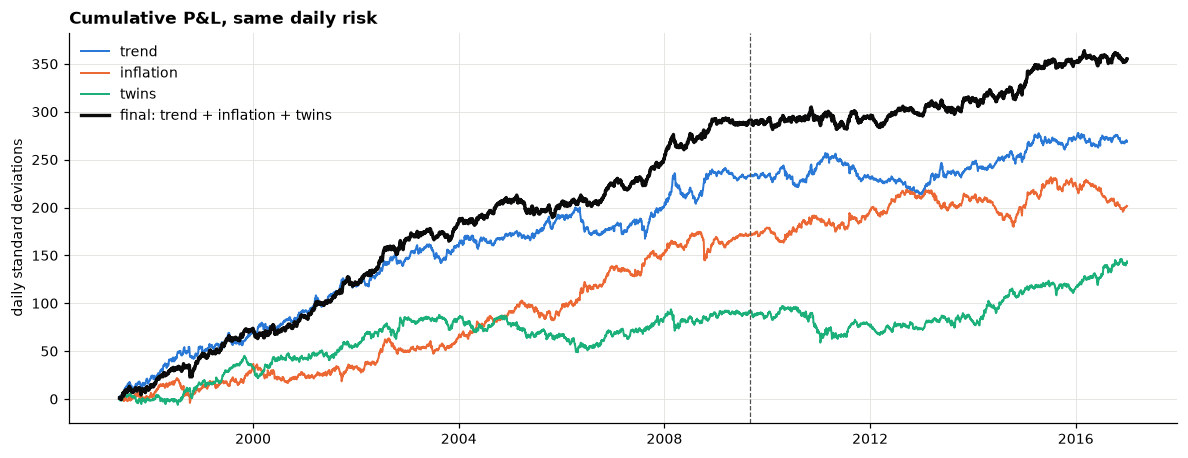

In [3]:
R = fv.R
fig, ax = plt.subplots(figsize=(13, 4.6))
for k in ["trend only", "inflation only", "twins only"]:
    ax.plot(R.index, (R[k] / R[k].std()).cumsum(), color=COL[k], lw=1.3, label=k.replace(" only", ""))
ax.plot(R.index, (R[fv.FINAL] / R[fv.FINAL].std()).cumsum(), color=INK, lw=2.2, label=f"final: {fv.FINAL}")
ax.axvline(pd.Timestamp(fv.E2), color=INK2, lw=0.8, ls="--")
ax.set_title("Cumulative P&L, same daily risk"); ax.set_ylabel("daily standard deviations"); ax.legend(loc="upper left")
plt.show()

## 3. Era by era

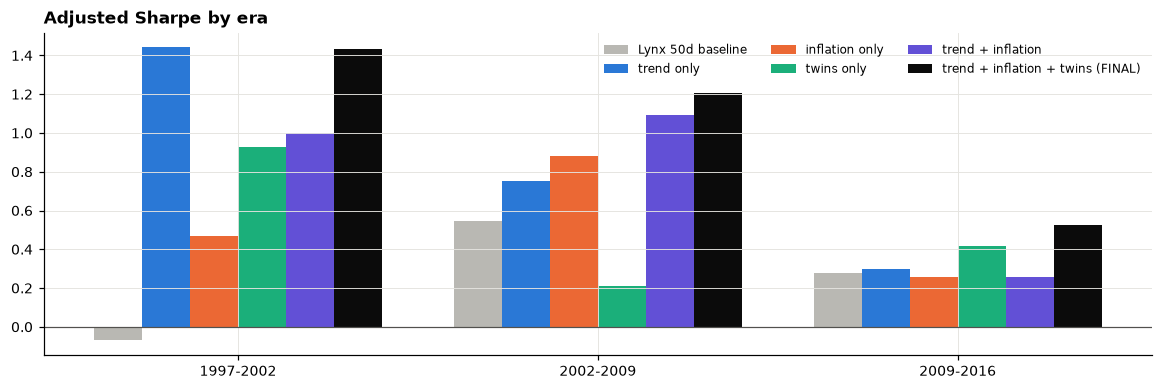

In [4]:
names = ["Lynx 50d baseline", "trend only", "inflation only", "twins only", "trend + inflation", fv.FINAL + " (FINAL)"]
t = fv.main.set_index("model").loc[names, ERA_COLS]
fig, ax = plt.subplots(figsize=(13, 3.8))
w = 0.8 / len(names)
shades = ["#b9b8b3", COL["trend only"], COL["inflation only"], COL["twins only"], "#6250d6", INK]
for i, (m, c) in enumerate(zip(names, shades)):
    ax.bar(np.arange(len(ERA_COLS)) + i * w, t.loc[m], w, color=c, label=m)
ax.set_xticks(np.arange(len(ERA_COLS)) + 0.4 - w / 2, ERA_COLS); ax.axhline(0, color=INK2, lw=0.8)
ax.set_title("Adjusted Sharpe by era"); ax.legend(ncol=3, fontsize=8)
plt.show()

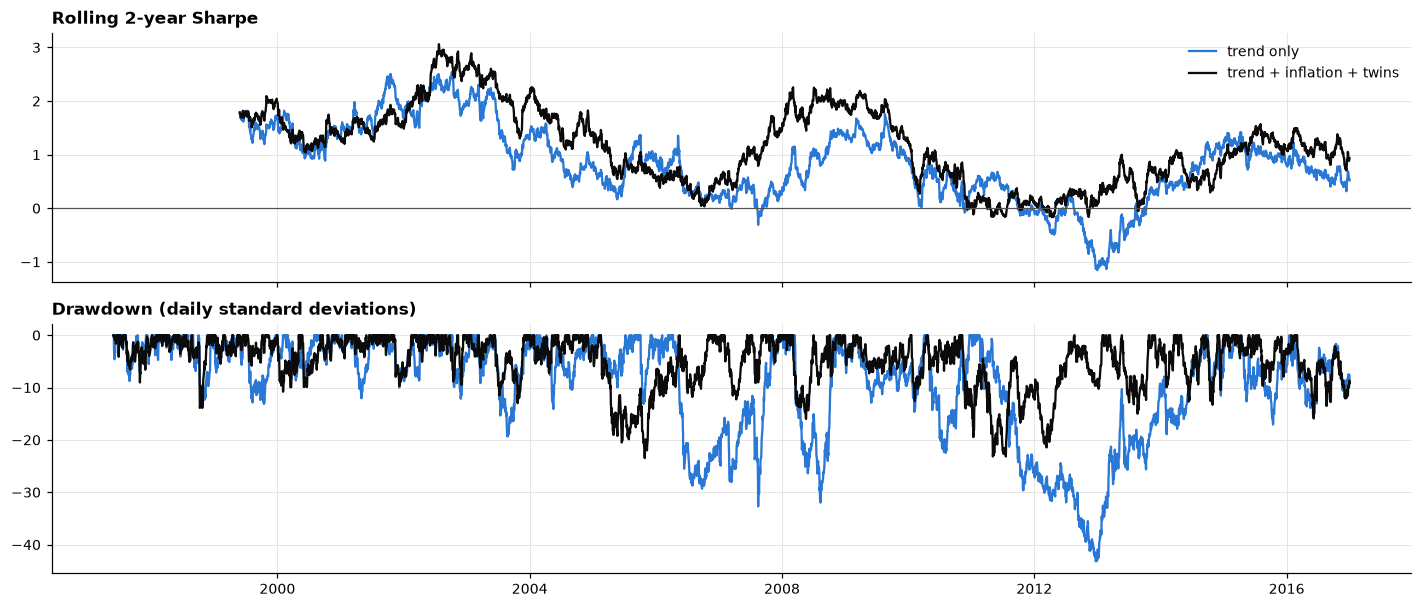

In [5]:
# rolling 2-year Sharpe and drawdown: final vs trend only
fig, axes = plt.subplots(2, 1, figsize=(13, 5.6), sharex=True)
for k, c in [("trend only", COL["trend only"]), (fv.FINAL, INK)]:
    r = R[k] / R[k].std()
    axes[0].plot(r.index, r.rolling(520).mean() / r.rolling(520).std() * np.sqrt(260), color=c, label=k)
    cum = r.cumsum(); axes[1].plot(r.index, cum - cum.cummax(), color=c, label=k)
axes[0].axhline(0, color=INK2, lw=0.8); axes[0].set_title("Rolling 2-year Sharpe"); axes[0].legend()
axes[1].set_title("Drawdown (daily standard deviations)")
plt.tight_layout(); plt.show()

## 4. Do the sleeves overlap?
Daily P&L correlation, each sleeve run alone through the same sizing. Near zero means they are separate bets.

In [6]:
show(fv.c)

daily P&L,trend only,inflation only,twins only,final model
trend only,1.00,-0.10,-0.03,0.49
inflation only,-0.10,1.00,0.02,0.48
twins only,-0.03,0.02,1.00,0.62
final model,0.49,0.48,0.62,1.00


## 5. The one choice made on data: twins in or out
The rule was set before scoring: keep the twins sleeve only if it raises adjusted Sharpe on the selection window. The last era is not used.

In [7]:
show(fv.sel)

model,1997-2009
trend + inflation,1.12
trend + inflation + twins,1.30


## 6. Inflation lookback plateau
The defaults (bonds 60, stocks 120) were fixed up front and are not changed by this table. It only checks that neighbouring lookbacks give similar scores, so the result does not hang on one number. The last two rows split the sleeve into its bond rule and its stock rule.

In [8]:
show(fv.plateau, grad=["full"] + ERA_COLS)

bonds k,stocks k,model,default,full,1997-2002,2002-2009,2009-2016
20,120,inflation only,,0.54,0.40,0.81,0.19
20,120,trend + inflation,,0.87,0.98,1.12,0.27
60,120,inflation only,yes,0.61,0.47,0.88,0.26
60,120,trend + inflation,yes,0.87,1.00,1.09,0.26
120,120,inflation only,,0.59,0.67,0.65,0.44
120,120,trend + inflation,,0.85,1.06,0.98,0.21
60,250,inflation only,,0.46,0.14,0.90,0.18
60,250,trend + inflation,,0.85,1.12,1.03,0.35
60,-,"bonds rule alone, k=60",,0.39,-0.04,0.95,-0.03
-,120,"stocks rule alone, k=120",,0.42,0.49,0.68,0.10


**How to read it**
- Inside the combined model the neighbours score about the same: a plateau, not a peak.
- On its own the inflation sleeve is weaker in the first and last eras, and **the bond rule earns almost all of its money in the middle era**. The stock rule is steadier. This is the main open risk of the model.

## 7. Leak test
Positions recomputed on histories cut at 30 / 50 / 70 / 90 / 97% (prices and macro cut at the same date) must equal the full run on every shared row.

In [9]:
show(fv.leak)

model,result,largest relative difference
trend + inflation + twins (final),PASS,0.0e+00
inflation only,PASS,0.0e+00


## 8. Is the gain over trend real? Block bootstrap
2000 paired resamples of 60-day blocks of daily P&L.

quantity,point,90% interval
final model,1.06,0.75 to 1.37
trend only,0.78,0.44 to 1.08
final minus trend only,0.28,-0.02 to 0.57


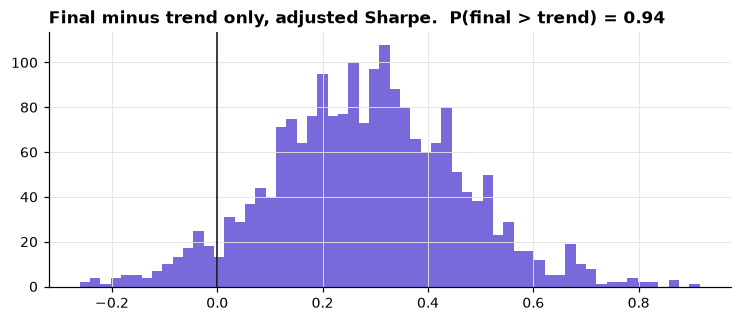

In [10]:
show(fv.boot)
diff = fv.bf - fv.bt
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(diff, bins=60, color="#6250d6", alpha=0.85); ax.axvline(0, color=INK, lw=1)
ax.set_title(f"Final minus trend only, adjusted Sharpe.  P(final > trend) = {fv.p_beat:.2f}")
plt.show()

## 9. Where the P&L comes from
Per asset: Sharpe of the asset's P&L inside the final model, and its position bias.

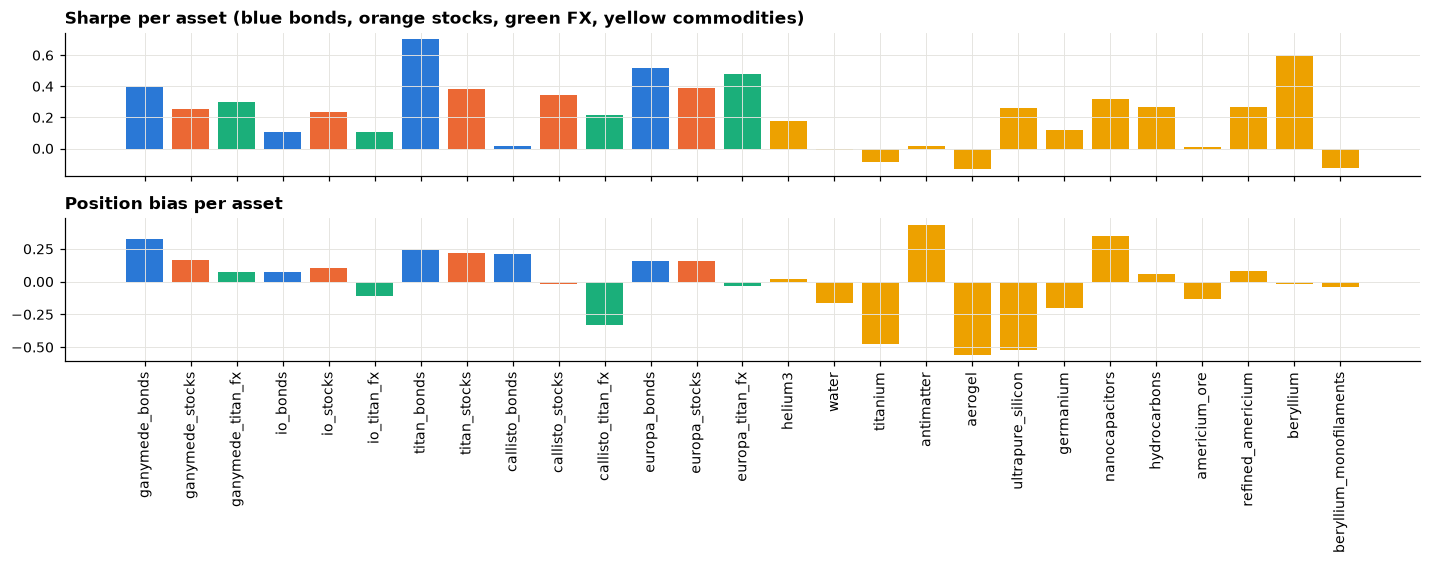

assets with positive Sharpe: 23 of 27


In [11]:
pos = fv.POS[fv.FINAL].filter(pl.col("AsOfDate") >= fv.START)
k = ev.calc_key_figures(pos, fv.prices, key_figures=["sharpe_per_instrument", "position_bias_per_instrument"])
sh, bi = pd.Series(k["sharpe_per_instrument"]), pd.Series(k["position_bias_per_instrument"])
cc = {"bonds": "#2a78d6", "stocks": "#eb6834", "fx": "#1baf7a", "commodity": "#eda100"}
cols = [cc[fm.asset_class(a)] for a in sh.index]
fig, axes = plt.subplots(2, 1, figsize=(13, 5.2), sharex=True)
axes[0].bar(sh.index, sh, color=cols); axes[0].set_title("Sharpe per asset (blue bonds, orange stocks, green FX, yellow commodities)")
axes[1].bar(bi.index, bi, color=cols); axes[1].set_title("Position bias per asset"); axes[1].tick_params("x", rotation=90)
plt.tight_layout(); plt.show()
print(f"assets with positive Sharpe: {(sh > 0).sum()} of {len(sh)}")

## 10. Lynx's own dashboard for the final model

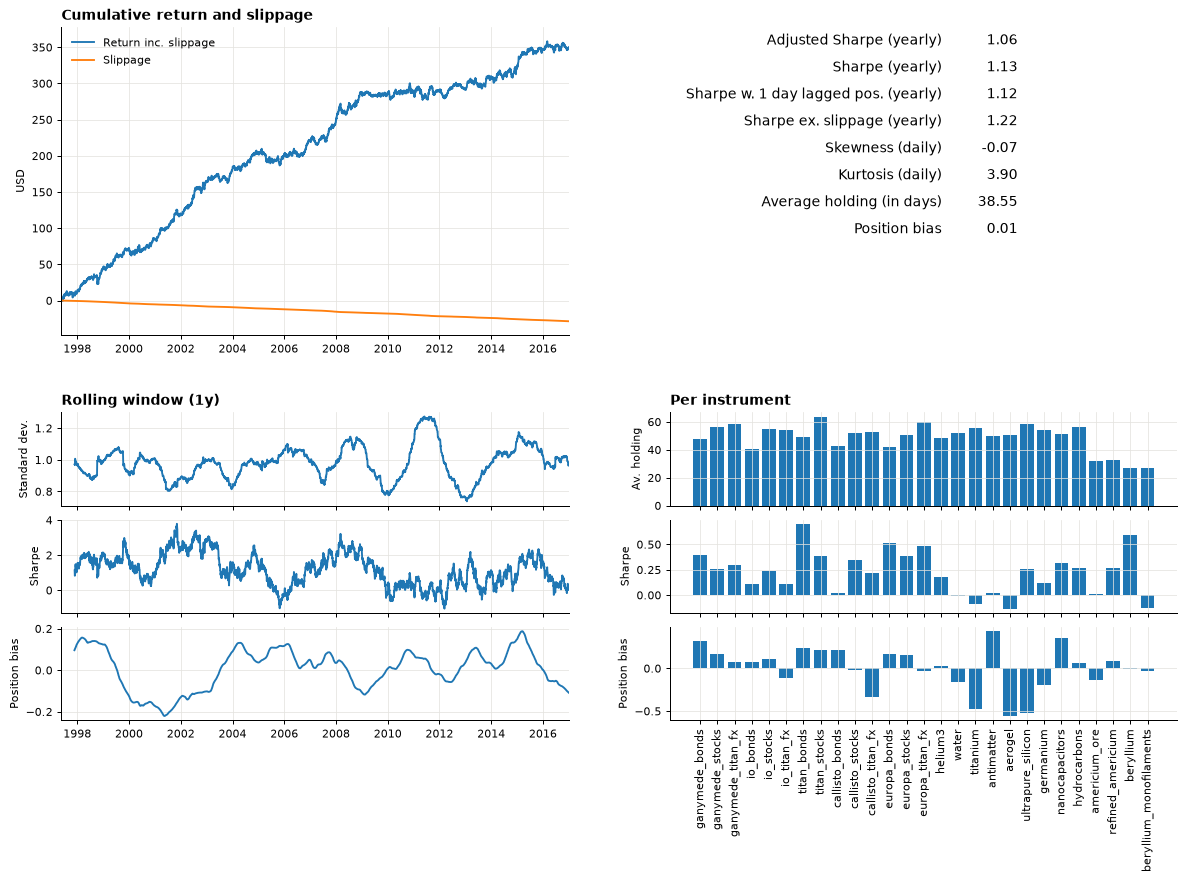

In [12]:
import io
from IPython.display import Image
buf = io.BytesIO()
ev.plot_key_figures(pos, fv.prices).savefig(buf, format="png", dpi=90, bbox_inches="tight")
display(Image(buf.getvalue()))

## 11. Kristofer's stop as an overlay
On stocks and bonds, when Kristofer's rule is stopped out (EMA 10/100 trend up, his position flat), a long position in the final model is cut to zero. His logic is imported unchanged. It is **not** part of the submitted model: the cut is a hard on/off switch, it has not been leak-tested here, and its gain sits in the first era, so it needs a closer look before it goes in.

In [13]:
show(fv.main[fv.main["model"].str.contains("FINAL|Kristofer")], grad=["full"] + ERA_COLS)
print(f"share of stock/bond days where his rule is stopped out: {fv.stopped_share:.1%}")

model,full,1997-2002,2002-2009,2009-2016,sharpe,sharpe 1d lag,2x costs,skew,kurt,holding d,bias
trend + inflation + twins (FINAL),1.06,1.43,1.20,0.53,1.13,1.12,0.98,-0.07,3.90,38.55,0.01
final + Kristofer stop overlay,1.10,1.74,1.22,0.53,1.15,1.16,1.01,-0.02,3.82,37.66,-0.00


share of stock/bond days where his rule is stopped out: 3.3%


## 12. Verdict and next steps
- The combined model beats trend alone in the full period and in the selection window, with lower kurtosis and no long tilt. It passes the leak test.
- The bootstrap interval for the gain over trend touches zero: the gain is likely, not certain.
- Weakest points: the last era for every sleeve, the bond inflation rule earning in one era only, and how much of the gain comes from the twins sleeve.

Open work is listed in `NEXT_STEPS.md` in this folder.